In [1]:
import wave
from pathlib import Path
import numpy as np

path = Path("../data/eval_data_test/Sander/test/section_00_0000.wav")
with wave.open(str(path)) as w:
    sr = w.getframerate()
    audio = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16).reshape(-1, w.getnchannels())

print(path.name, sr, audio.shape)

section_00_0000.wav 16000 (160000, 2)


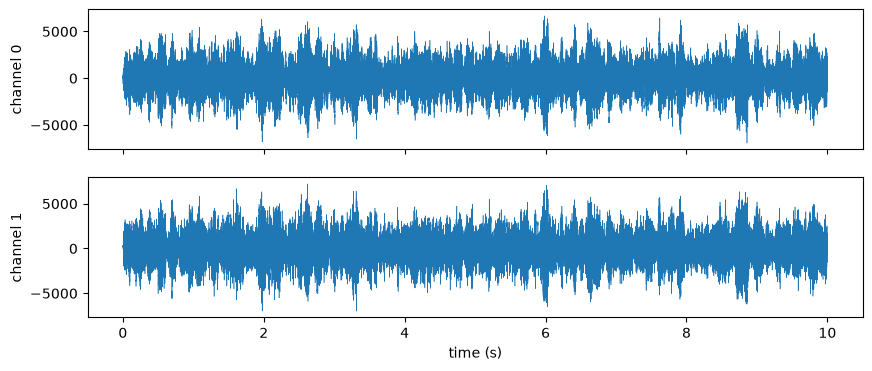

int16 -6990 7209


In [2]:
import matplotlib.pyplot as plt

t = np.arange(len(audio)) / sr
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 4))
for ch, ax in enumerate(axes):
    ax.plot(t, audio[:, ch], lw=0.4)
    ax.set_ylabel(f"channel {ch}")
axes[-1].set_xlabel("time (s)")
plt.show()

print(audio.dtype, audio.min(), audio.max())

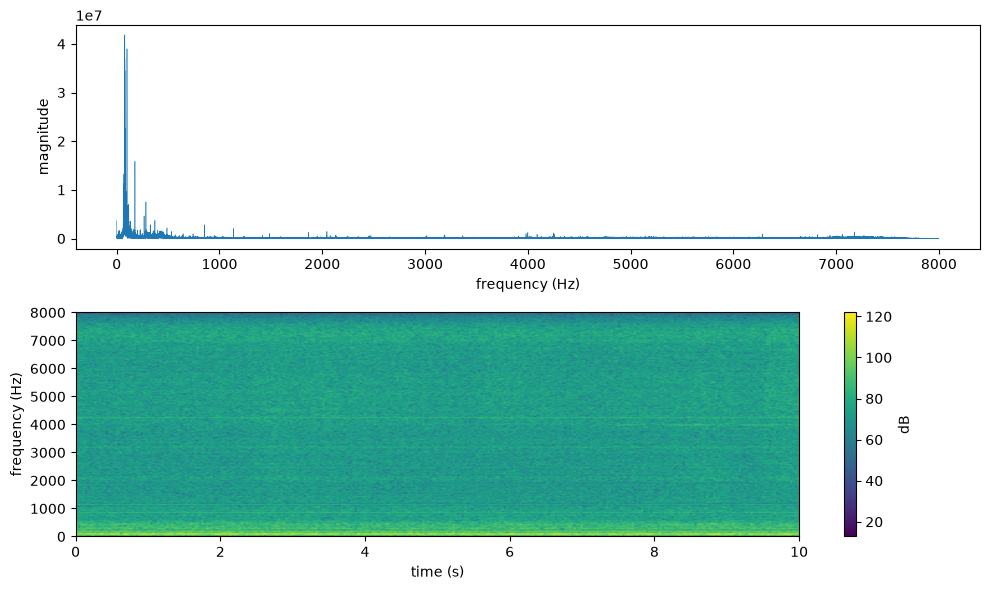

In [3]:
x = audio[:, 0].astype(float)  # near microphone

# 1) FFT: whole clip -> one spectrum (which frequencies, no timing)
freqs = np.fft.rfftfreq(len(x), 1 / sr)
mag = np.abs(np.fft.rfft(x))

# 2) STFT: short windows -> spectrogram (which frequencies, when)
win, hop = 1024, 512
frames = np.lib.stride_tricks.sliding_window_view(x, win)[::hop] * np.hanning(win)
spec = np.abs(np.fft.rfft(frames, axis=1)).T
spec_db = 20 * np.log10(spec + 1e-9)

fig, (a, b) = plt.subplots(2, 1, figsize=(10, 6))
a.plot(freqs, mag, lw=0.4)
a.set_xlabel("frequency (Hz)")
a.set_ylabel("magnitude")
im = b.imshow(spec_db, origin="lower", aspect="auto", extent=[0, len(x) / sr, 0, sr / 2])
b.set_xlabel("time (s)")
b.set_ylabel("frequency (Hz)")
fig.colorbar(im, ax=b, label="dB")
plt.tight_layout()
plt.show()

(64, 311)


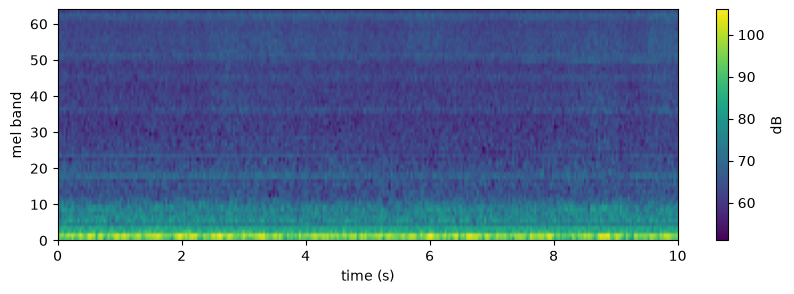

In [4]:
import librosa

n_mels = 64
mel = librosa.feature.melspectrogram(y=x, sr=sr, n_fft=win, hop_length=hop, n_mels=n_mels, center=False, power=2.0)
mel_db = librosa.power_to_db(mel, top_db=None)
print(mel.shape)

plt.figure(figsize=(10, 3))
plt.imshow(mel_db, origin="lower", aspect="auto", extent=[0, len(x) / sr, 0, n_mels])
plt.xlabel("time (s)")
plt.ylabel("mel band")
plt.colorbar(label="dB")
plt.show()

In [ ]:
fb = librosa.filters.mel(sr=sr, n_fft=win, n_mels=n_mels)  # the filterbank matrix: (64 bands, 513 FFT bins)
print(fb.shape, "non-zero entries:", (fb > 0).sum(), "of", fb.size)

fig, (a, b) = plt.subplots(2, 1, figsize=(10, 6))
a.imshow(fb, origin="lower", aspect="auto", extent=[0, sr / 2, 0, n_mels])
a.set_xlabel("FFT bin frequency (Hz)")
a.set_ylabel("mel band")
for i in [0, 10, 20, 40, 63]:  # a few rows of the matrix as lines
    b.plot(np.fft.rfftfreq(win, 1 / sr), fb[i], label=f"band {i}")
b.set_xlabel("FFT bin frequency (Hz)")
b.set_ylabel("weight")
b.legend()
plt.tight_layout()
plt.show()

fb[:5, :12]  # top-left corner of the actual numbers

# Autoencoder strategy

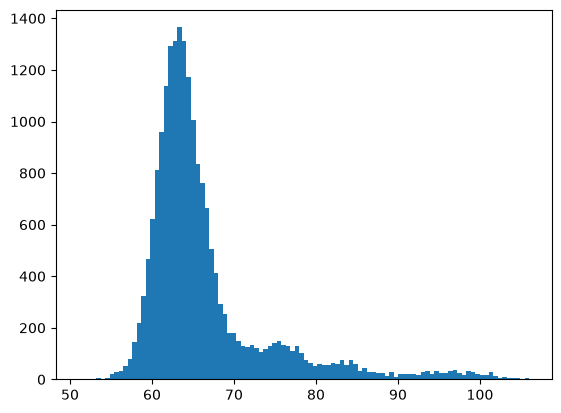

In [5]:
plt.hist(mel_db.flatten(), bins=100);

In [6]:
X = mel_db.T                              # (311 frames, 64 mel bands): one frame = one training sample
X = (X - X.mean(axis=0)) / X.std(axis=0)  # scale each band
X.shape

(311, 64)

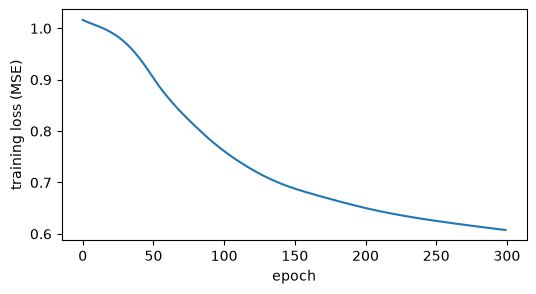

final loss: 0.6075625419616699


In [7]:
import torch
from torch import nn

torch.manual_seed(0)
Xt = torch.tensor(X, dtype=torch.float32)

# 64 -> 32 -> 8 -> 32 -> 64: squeeze through 8 numbers, then rebuild the input
ae = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 8), nn.ReLU(), nn.Linear(8, 32), nn.ReLU(), nn.Linear(32, 64))
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)

losses = []
for epoch in range(300):
    loss = nn.functional.mse_loss(ae(Xt), Xt)  # target = input
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())

plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("training loss (MSE)")
plt.show()

print("final loss:", losses[-1])

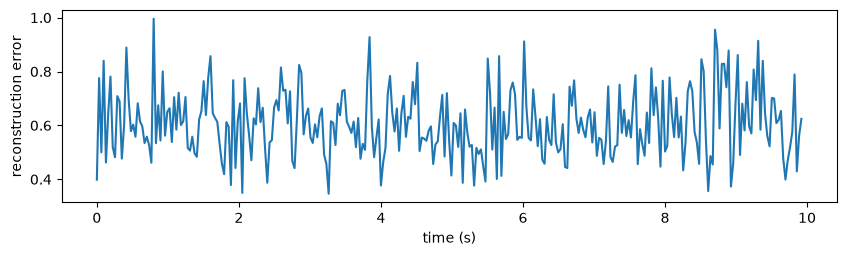

clip score: 0.60723794


In [8]:
with torch.no_grad():
    err = ((ae(Xt) - Xt) ** 2).mean(dim=1).numpy()  # reconstruction error per frame = anomaly score

plt.figure(figsize=(10, 2.5))
plt.plot(np.arange(len(err)) * hop / sr, err)
plt.xlabel("time (s)")
plt.ylabel("reconstruction error")
plt.show()

print("clip score:", err.mean())

# YAMNet (pretrained, inference only)

In [9]:
import csv
import tensorflow_hub as hub

yamnet = hub.load("https://tfhub.dev/google/yamnet/1")  # pretrained on AudioSet, no training here

wave_in = (audio[:, 0] / 32768.0).astype(np.float32)  # near mic, mono, float in [-1, 1], 16 kHz
scores, embeddings, _ = yamnet(wave_in)               # scores: (windows, 521 classes), embeddings: (windows, 1024)

class_names = [r["display_name"] for r in csv.DictReader(open(yamnet.class_map_path().numpy().decode()))]
scores.shape, embeddings.shape

C:\Users\Or\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


(TensorShape([20, 521]), TensorShape([20, 1024]))

In [10]:
import pandas as pd
import tensorflow as tf

fn = yamnet.signatures["serving_default"]
print("input :", fn.structured_input_signature[1])
print("output:", {k: v.shape for k, v in fn.structured_outputs.items()})  # scores, embeddings, log-mel

layers = pd.DataFrame(
    [(v.name.split(":")[0], tuple(v.shape), int(tf.size(v))) for v in fn.variables],
    columns=["variable", "shape", "params"],
)
display(layers)
print(f"{len(layers)} variables, {layers.params.sum():,} params")

input : {'waveform': TensorSpec(shape=(None,), dtype=tf.float32, name='waveform')}
output: {'output_0': TensorShape([None, 521]), 'output_1': TensorShape([None, 1024]), 'output_2': TensorShape([None, 64])}


,variable,shape,params
0,layer1/conv/kernel,"(3, 3, 1, 32)",288
1,layer1/conv/bn/beta,"(32,)",32
2,layer1/conv/bn/moving_mean,"(32,)",32
3,layer1/conv/bn/moving_variance,"(32,)",32
4,layer2/depthwise_conv/depthwise_kernel,"(3, 3, 32, 1)",288
...,...,...,...
105,layer14/pointwise_conv/bn/beta,"(1024,)",1024
106,layer14/pointwise_conv/bn/moving_mean,"(1024,)",1024
107,layer14/pointwise_conv/bn/moving_variance,"(1024,)",1024
108,dense/kernel,"(1024, 521)",533504


110 variables, 3,751,369 params


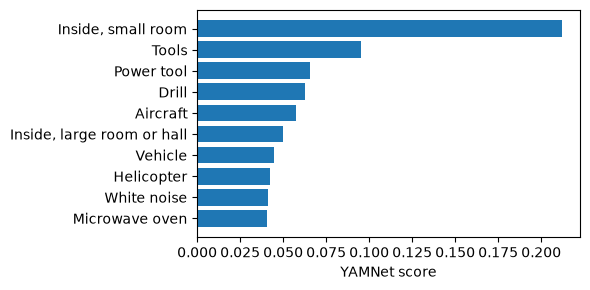

embedding of the clip: (1024,)


In [11]:
mean_scores = scores.numpy().mean(axis=0)  # average over the 20 windows -> one score per class
top = mean_scores.argsort()[::-1][:10]

plt.figure(figsize=(6, 3))
plt.barh([class_names[i] for i in top][::-1], mean_scores[top][::-1])
plt.xlabel("YAMNet score")
plt.tight_layout()
plt.show()

print("embedding of the clip:", embeddings.numpy().mean(axis=0).shape)

# Anomaly models on YAMNet embeddings (MOCK data)
Synthetic 1024-dim embeddings stand in for real YAMNet output, so the models can be compared quickly. Replace `X_train` / `X_test` / `y_test` with real embeddings later.

In [12]:
import numpy as np
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(0)
D = 1024  # YAMNet embedding size
mix = rng.normal(size=(8, D))  # normal sound has a few "operating modes"
def clips(n, shift=0.0):
    x = mix[rng.integers(0, 8, n)] * 0.5 + rng.normal(size=(n, D))
    if shift:
        x[:, rng.choice(D, 100, replace=False)] += shift  # anomaly = a subset of dims drifts
    return x
X_train = clips(300)
X_test = np.vstack([clips(100), clips(100, shift=0.8)])
y_test = np.r_[np.zeros(100), np.ones(100)]  # 1 = anomaly

sc = StandardScaler().fit(X_train)
Xtr, Xte = sc.transform(X_train), sc.transform(X_test)

def knn_score(k=5):
    nn = NearestNeighbors(n_neighbors=k).fit(Xtr)
    return nn.kneighbors(Xte)[0].mean(axis=1)  # mean distance to k nearest normal clips

models = {}
models["kNN"] = knn_score()
lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Xtr)
models["LOF"] = -lof.score_samples(Xte)
iso = IsolationForest(n_estimators=300, random_state=0).fit(Xtr)
models["IsolationForest"] = -iso.score_samples(Xte)
oc = OneClassSVM(gamma="scale", nu=0.05).fit(Xtr)
models["OneClassSVM"] = -oc.score_samples(Xte)
pca = PCA(n_components=32).fit(Xtr)
rec = pca.inverse_transform(pca.transform(Xte))
models["PCA recon"] = ((Xte - rec) ** 2).mean(axis=1)
gmm = GaussianMixture(n_components=8, covariance_type="diag", random_state=0).fit(Xtr)
models["GMM"] = -gmm.score_samples(Xte)

import pandas as pd
res = pd.Series({n: roc_auc_score(y_test, s) for n, s in models.items()}).sort_values(ascending=False)
print(res.round(3))

PCA recon          0.854
kNN                0.853
LOF                0.833
OneClassSVM        0.825
GMM                0.803
IsolationForest    0.649
dtype: float64
